
<h1 style="text-align:center;">Ejercicio Práctico</h1>

<p style="text-align:center;">05-11-2026</p>

<p style="text-align:center;">
  <img src="img/ITQ.png" width="500">
</p>

# 1. Práctica Académica

## Normalización y Estandarización de Datos en Inteligencia Artificial

**Nombre:** Nikolay Misael De La Cruz Melendres

**Asignatura:** Fundamentos de Machine Learning

**Docente:** Elvis David Pachacama Cabezas

**Tema:** Análisis y aplicación de técnicas de normalización y estandarización en conjuntos de datos para modelos de aprendizaje automático.

**Link Repositorio:** [NikolayDlc/fundamentosMachine](https://github.com/NikolayDlc/fundamentosMachine)



# 2. Objetivos

## Objetivo general

Aplicar técnicas de normalización y estandarización de datos mediante herramientas de Python para comprender su importancia en la preparación de datos para modelos de aprendizaje automático.

## Objetivos específicos

- Identificar las diferencias de escala entre variables numéricas.
- Aplicar la normalización Min-Max.
- Aplicar la estandarización Z-score.
- Analizar la importancia del preprocesamiento en Machine Learning.
- Comparar visualmente los datos originales, normalizados y estandarizados.


In [1]:

# Importación de librerías

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn import preprocessing




**Pandas (pd):** Permite trabajar con tablas de datos llamadas DataFrames, analizar columnas y realizar operaciones de limpieza.

**NumPy (np):** Permite realizar operaciones matemáticas con arreglos y matrices numéricas.

**Seaborn (sns):** Permite crear gráficos estadísticos para explorar y comparar datos.

**Matplotlib (plt):** Permite crear y personalizar gráficos, agregando títulos, etiquetas y tamaños.

**Scikit-learn (sklearn):** Es una librería de Machine Learning que proporciona conjuntos de datos y herramientas de preprocesamiento.

**load_iris:** Permite cargar el conjunto de datos Iris incluido en Scikit-learn.

**preprocessing:** Contiene herramientas como MinMaxScaler() y StandardScaler() para transformar los datos numéricos.


In [2]:
# Crear la carpeta dataset

import os

os.makedirs("dataset", exist_ok=True)

# Cargar el dataset Iris incluido en Scikit-learn

iris = load_iris()

# Crear un DataFrame con los nombres de columnas
# que utiliza el ejercicio

df_iris = pd.DataFrame(
    iris.data,
    columns=[
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
)

# Agregar identificador y especie

df_iris.insert(
    0, "Id", np.arange(1, len(df_iris) + 1)
)

df_iris["Species"] = [
    "Iris-" + iris.target_names[i]
    for i in iris.target
]

# Guardar los datos en un archivo CSV

df_iris.to_csv("dataset/Iris.csv", index=False)

print("Dataset Iris guardado correctamente.")

Dataset Iris guardado correctamente.


In [3]:
# Cargar el conjunto de datos

df = pd.read_csv("dataset/Iris.csv")

# Mostrar las primeras cinco filas

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**Iris** es un conjunto de datos utilizado para estudiar clasificación y preparación de datos en Machine Learning. Contiene 150 observaciones de flores pertenecientes a tres especies.
Cada flor tiene cuatro características numéricas:
- **SepalLengthCm:** longitud del sépalo en centímetros.
- **SepalWidthCm:** anchura del sépalo en centímetros.
- **PetalLengthCm:** longitud del pétalo en centímetros.
- **PetalWidthCm:** anchura del pétalo en centímetros.

La columna **Species** indica la especie de cada flor.

**pd.read_csv():** permite cargar un archivo CSV en un DataFrame.

**df.head():** muestra las primeras cinco filas para revisar cómo están organizados los datos.

**DataFrame:** es una estructura de Pandas que organiza la información en filas y columnas.

In [4]:
# Eliminar la columna Id porque no será utilizada
# como característica para el análisis

if "Id" in df.columns:
    df = df.drop(columns=["Id"])

# Comprobar las columnas restantes

print(df.columns)

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')


**df.columns:** Permite conocer los nombres de las columnas del DataFrame.

**df.drop(columns=["Id"]):** Devuelve un DataFrame sin la columna Id.

**if "Id" in df.columns:** Comprueba si la columna existe antes de intentar eliminarla.


In [5]:
# Mostrar información general del dataset

df.info()

# Verificar la cantidad de valores nulos
# en cada columna

print("\nValores nulos por columna:")

print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB

Valores nulos por columna:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


**df.info():** Permite revisar:
- Cantidad de registros.
- Nombres de las columnas.
- Cantidad de valores no nulos.
- Tipos de datos.

**df.isnull().sum():** Permite contar los valores faltantes en cada columna.

**isnull():** identifica los valores nulos.

**sum():** cuenta cuántos valores nulos hay.

In [6]:
# Separar características y variable objetivo

X = df.drop(columns=["Species"])

y = df["Species"]

# Mostrar las primeras filas de las características

X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**X:** Contiene las características numéricas de las flores:

- Longitud del sépalo.
- Anchura del sépalo.
- Longitud del pétalo.
- Anchura del pétalo.

**y:** Contiene la variable objetivo, que en este caso es la especie de la flor.


In [7]:
# Análisis exploratorio de las características

X.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


La instrucción X.describe() permite obtener estadísticas descriptivas de las características numéricas. Entre ellas encontramos:

- **count:** cantidad de valores no nulos.
- **mean:** media o promedio.
- **std:** desviación estándar, que mide la dispersión respecto a la media.
- **min:** valor mínimo.
- **25%:** primer cuartil.
- **50%:** mediana.
- **75%:** tercer cuartil.
- **max:** valor máximo.

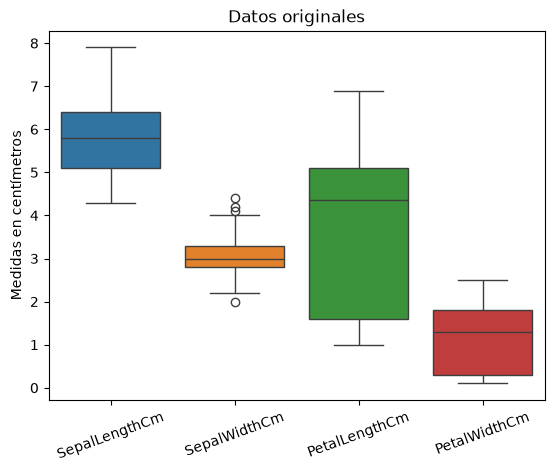

In [8]:
# Dibujar los datos originales

sns.boxplot(data=X)

# Agregar título y etiquetas

plt.title("Datos originales")
plt.ylabel("Medidas en centímetros")
plt.xticks(rotation=20)

# Mostrar gráfico

plt.show()

El gráfico de cajas o boxplot permite observar la distribución de las características numéricas. Podemos identificar:

- La posición de la mediana.
- La dispersión de los datos.
- Los cuartiles.
- Posibles valores atípicos.

In [9]:
# Normalizar el conjunto de datos

normalizer = preprocessing.MinMaxScaler()

X_norm = normalizer.fit_transform(X)

# Convertir el resultado a DataFrame

X_norm = pd.DataFrame(
    X_norm,
    columns=X.columns
)

# Mostrar las primeras cinco filas

X_norm.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


**MinMaxScaler():** Es una herramienta de Scikit-learn que transforma las características numéricas a un intervalo determinado, generalmente entre 0 y 1.

**fit_transform():** Realiza dos operaciones:

1. **fit():** calcula los mínimos y máximos de las columnas.
2. **transform():** transforma los valores utilizando esos parámetros.

**pd.DataFrame():** Convierte la matriz normalizada en un DataFrame de Pandas.

**columns=X.columns:** Permite conservar los nombres originales de las características.

**X_norm.head():** Muestra las primeras cinco filas de los datos normalizados.

In [10]:

# Mostrar estadísticas de los datos normalizados

X_norm.describe()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,0.428704,0.440556,0.467458,0.458056
std,0.230018,0.181611,0.299203,0.317599
min,0.000000,0.000000,0.000000,0.000000
25%,0.222222,0.333333,0.101695,0.083333
50%,0.416667,0.416667,0.567797,0.500000
75%,0.583333,0.541667,0.694915,0.708333
max,1.000000,1.000000,1.000000,1.000000


In [11]:
# Estandarización del conjunto de datos

standardizer = preprocessing.StandardScaler()

# Aplicar estandarización

X_std = standardizer.fit_transform(X)

# Convertir el resultado a DataFrame

X_std = pd.DataFrame(
    X_std,
    columns=X.columns
)

# Mostrar las primeras cinco filas

X_std.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


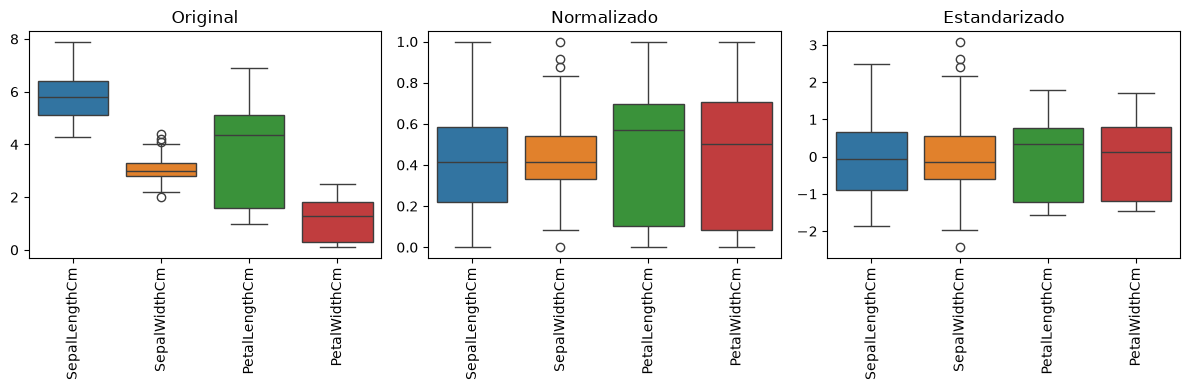

In [12]:

# Comparación visual

plt.figure(figsize=(12, 4))

# Datos originales

plt.subplot(1, 3, 1)
sns.boxplot(data=X)
plt.title("Original")
plt.xticks(rotation=90)

# Datos normalizados

plt.subplot(1, 3, 2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")
plt.xticks(rotation=90)

# Datos estandarizados

plt.subplot(1, 3, 3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()
